# Learning a Feature Fast Once It Has the Right Inputs

> **Overview.** With 8 target LTUs and LTUs that read exactly the right inputs, what makes a new LTU learn its feature
> fast: a higher initial step-size, initial weights from the linear learner, or adding the linear prediction back to its
> error?

The first of three pieces toward searching over features with many target LTUs (`04_feature_search.ipynb`): an LTU that
reads the right inputs should learn its feature quickly. With 8 target LTUs, LTUs reading exactly one target LTU's
inputs, added once the linear learner has converged, have barely started learning after 1M steps
(`03_several_targets.ipynb`): the linear learner has already taken the linear part of the target, so what is left
pushes an LTU toward its target LTU only in proportion to the square of how well their input weights already agree.
Which changes to a new LTU make it learn fast?

**Problem.** As in `03_several_targets.ipynb`, with $K = 8$: $N = 1000$ standard normal inputs, and the target is
$\frac{1}{\sqrt{8}} \sum_{k=1}^{8} \mathrm{sign}(w_k \cdot x_k)$ plus $N(0, 0.1^2)$ noise, where target LTU $k$ reads
$x_k$, the $k$-th block of 10 inputs, with random $\pm 1$ weights $w_k$. The best possible RMSE is 0.1 (dotted line),
and the best linear learner's about 0.61 (dashed line). Each seed has its own target weights.

**Learner.** As in `03_several_targets.ipynb`: the linear learner, a bias, and 32 hidden LTUs (sigmoid derivative
backward) with fixed shadow output weights, +1 and -1 alternately, standardized online; network Autostep
(`squared_inputs`, initial step-size $10^{-4}$, meta step-size 0.02, $\tau = 10^4$). The linear learner learns alone for
the first 100k steps; then the LTUs are added and everything learns for 500k more steps. Every LTU reads the right inputs:
each pair of LTUs (shadow weights +1 and -1) reads one target LTU's 10 inputs and a bias, 4 LTUs per target LTU.

**Changes to the new LTUs**, one idea at a time, each against the *baseline*: input weights LeCun uniform,
$U(-\sqrt{3/10}, \sqrt{3/10})$, with initial step-size $10^{-4}$, as in `03_several_targets.ipynb`.
- *Initial step-size* of the LTUs' input weights, higher than the rest of the network's.
- *Initial input weights* from the linear learner: its weights on the inputs the LTU reads; those weights scaled to
  norm 1, the expected norm of LeCun uniform weights (its direction); or LeCun uniform magnitudes with the signs of its
  weights. Each times the LTU's shadow weight, so the LTU starts out agreeing with its shadow weight.
- *Linear prediction added back*: the error that reaches the LTUs is the network's error plus $\lambda$ times the linear
  learner's prediction, as if the linear learner had learned only $1 - \lambda$ of what it has; with $\lambda = 1$ the
  LTUs learn as if there were no linear learner. Either for a while after the LTUs are added and then $\lambda = 0$, or
  throughout. Nothing else learns from this changed error.
- *Combined* with a higher initial step-size: each of the last two ideas with the input weights' initial step-size at
  $10^{-2}$ (dashed) and $3 \times 10^{-2}$ (solid).

**Runs.** 5 seeds per configuration; the same seed gives every run the same samples and target weights. *Linear
learner* (baseline): no LTUs. Curves are the mean over seeds of the RMSE averaged over windows of 1k steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 1000
N_TARGETS = 8                        # target LTUs
N_SOURCES = 10                       # each target LTU reads its own block of N_SOURCES inputs, from the first
NOISE_STD = 0.1                      # observation noise on the target: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # the best linear learner's RMSE

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32                          # hidden LTUs, each pair reading one target LTU's inputs

# --- Experiment ---
LINEAR_STEPS = 100_000               # the linear learner learns alone for this many steps, then the LTUs are added
NUM_STEPS = 500_000                  # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5

## Learner

In [3]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped (units,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, 1 (the bias)], of which they read those in `reads`;
    # w['output'] is the output's weights over [inputs (the linear learner), the hidden units, 1]. `mask` says which of
    # the output's connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (slots, N_INPUTS + 1), 'output': (1, N_INPUTS + slots + 1)}
    reads: jax.Array            # (slots, N_INPUTS + 1)
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (slots,): each hidden unit's shadow output weight, +-1, or 0 for an empty slot


def init_net(key, units, slots):
    # `units` hidden units in `slots` slots, the rest left empty, each pair reading the inputs of one of the N_TARGETS
    # target LTUs in turn and the bias; their shadow weights +1 and -1 alternately, their input weights LeCun uniform,
    # U(-sqrt(3 / N_SOURCES), sqrt(3 / N_SOURCES)); every other weight at 0.
    target = jnp.arange(slots) // 2 % N_TARGETS
    reads = jnp.append(jnp.arange(N_INPUTS) // N_SOURCES == target[:, None], jnp.ones((slots, 1), bool), axis=1)
    shadow = jnp.where(jnp.arange(slots) < units, jnp.where(jnp.arange(slots) % 2 == 0, 1.0, -1.0), 0.0)
    mask = jnp.concatenate([jnp.ones(N_INPUTS, bool), jnp.zeros(slots, bool), jnp.ones(1, bool)])[None]
    w = {'hidden': (jax.random.uniform(key, (slots, N_INPUTS + 1), minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / N_SOURCES) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((1, N_INPUTS + slots + 1))}
    stats = Stats(jnp.full(slots, 0.5), jnp.zeros(slots), jnp.zeros(slots))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow)


RANDOM, LINEAR, DIRECTION, SIGNS = 0, 1, 2, 3   # a new LTU's input weights: LeCun uniform, the linear learner's,
                                                # their direction, or their signs


class Variant(NamedTuple):
    # How the hidden units start when they are added, and the error they learn from.
    init: int = RANDOM          # RANDOM, LINEAR, DIRECTION or SIGNS
    input_step: float = INIT_STEP_SIZE   # initial step-size of their input weights
    added_back: float = 0.0     # λ: this times the linear learner's prediction is added to the error reaching them...
    until: int = 0              # ...for this many steps after they are added


def add_units(net, variant):
    # The hidden units' input weights at addition: unchanged (RANDOM), the linear learner's weights on the inputs they
    # read (LINEAR), those weights scaled to norm 1, the expected norm of LeCun uniform weights (DIRECTION), or their
    # LeCun uniform magnitudes with the signs of those weights (SIGNS), each times the unit's shadow weight; their input
    # weights' step-sizes start at variant.input_step.
    linear = net.shadow[:, None] * jnp.append(net.w['output'][0, :N_INPUTS], 0.0) * net.reads
    direction = linear / jnp.linalg.norm(linear, axis=1, keepdims=True)
    hidden = jnp.select([variant.init == LINEAR, variant.init == DIRECTION, variant.init == SIGNS],
                        [linear, direction, jnp.abs(net.w['hidden']) * jnp.sign(linear)], net.w['hidden'])
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(variant.input_step), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def learn(net, x, y, added_back):
    # One online network-Autostep update on half the squared error, each shadow weight standing in for its hidden
    # unit's output weight in the backward pass while the real one is smaller in magnitude, and added_back times the
    # linear learner's prediction added to the error reaching the hidden units. Returns the new network and the squared
    # error on this sample, before learning from it. `probe` is zero; its gradient is the error arriving at each hidden
    # unit.
    units = len(net.shadow)

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}
        b = ltu(w['hidden'] @ jnp.append(x, 1.0))
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = h + probe
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][0, N_INPUTS:N_INPUTS + units]
        back_w = jnp.where(jnp.abs(unit_w) < 1.0, net.shadow, unit_w) * net.mask[0, N_INPUTS:-1]
        through_back = jnp.sum(back_w * a)
        prediction = (w['output'] @ jax.lax.stop_gradient(source) + through_back
                      - jax.lax.stop_gradient(through_back))
        to_hidden = jnp.sum(jax.lax.stop_gradient(back_w) * a)   # zero; its gradient reaches only the hidden units
        linear_prediction = jax.lax.stop_gradient(w['output'][0, :N_INPUTS] @ x)
        added = added_back * linear_prediction * (to_hidden - jax.lax.stop_gradient(to_hidden))
        sources = {'hidden': jnp.append(x, 1.0) * net.reads,
                   'output': jax.lax.stop_gradient(source)[None] * net.mask}
        return 0.5 * jnp.sum((prediction - y) ** 2) - added, (sources, jax.lax.stop_gradient(h), mean)

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, jnp.zeros(units))
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats), 2 * loss

## Training

In [4]:
def train(net, key, variant, add_step, num_steps):
    # num_steps online network-Autostep steps on targets from this seed's target LTUs, the hidden units added at
    # add_step as the variant says. Returns each window's mean squared error.
    target_key, key = jax.random.split(key)
    target_w = jax.random.rademacher(target_key, (N_TARGETS, N_SOURCES), dtype=float)

    def one_step(net, inputs):
        step, key = inputs
        x_key, noise_key = jax.random.split(key)
        x = jax.random.normal(x_key, (N_INPUTS,))
        blocks = x[:target_w.size].reshape(target_w.shape)
        y = (jnp.sum(jnp.where(jnp.sum(target_w * blocks, 1) > 0, 1.0, -1.0)) / np.sqrt(N_TARGETS)
             + NOISE_STD * jax.random.normal(noise_key, (1,)))
        net = net._replace(mask=net.mask.at[0, N_INPUTS:-1].set((step >= add_step) & (net.shadow != 0)))
        return learn(net, x, y, jnp.where(step - add_step < variant.until, variant.added_back, 0.0))

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        return net, mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = add_units(net, variant)
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def run(units, variants):
    # `units` hidden LTUs (none: the linear learner alone), started as each of the variants says, each on N_SEEDS
    # seeds, vmapped together. Seed s gives every run the same samples and target weights. Returns {variant: the RMSE
    # of each window from step 1, shaped (seed, window)}.
    seed = jnp.tile(jnp.arange(N_SEEDS), len(variants))
    stacked = Variant(*(jnp.repeat(jnp.array(v), N_SEEDS) for v in zip(*variants)))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    nets = jax.vmap(lambda k: init_net(k, units, max(units, 1)))(keys(0))
    train_all = jax.jit(jax.vmap(lambda n, k, v: train(n, k, v, LINEAR_STEPS, LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), stacked)
    return dict(zip(variants, np.sqrt(np.asarray(mse)).reshape(len(variants), N_SEEDS, -1)))

## Runs

In [5]:
BASELINE = Variant()
IDEAS = {   # each idea's variants, with the input weights' initial step-size at the baseline's unless the idea is that
    'Initial step-size of the LTUs\' input weights': {
        f'{s:g}': Variant(input_step=s) for s in (3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1)},
    'Initial input weights from the linear learner': {
        "the linear learner's weights": Variant(init=LINEAR),
        "the linear learner's direction": Variant(init=DIRECTION),
        "LeCun uniform magnitudes, the linear learner's signs": Variant(init=SIGNS)},
    'Linear prediction added back to the LTUs\' error': {
        'λ = 1 for the first 20k steps': Variant(added_back=1.0, until=20_000),
        'λ = 1 for the first 100k steps': Variant(added_back=1.0, until=100_000),
        'λ = 1 throughout': Variant(added_back=1.0, until=NUM_STEPS),
        'λ = 0.25 throughout': Variant(added_back=0.25, until=NUM_STEPS)},
}
COMBINED_STEPS = (1e-2, 3e-2)        # initial step-sizes of the input weights in the combinations: dashed, solid
COMBINED = {label: [variant._replace(input_step=s) for s in COMBINED_STEPS] for label, variant in {
    'LeCun uniform input weights': BASELINE,
    "the linear learner's direction": Variant(init=DIRECTION),
    "LeCun uniform magnitudes, the linear learner's signs": Variant(init=SIGNS),
    'λ = 1 for the first 20k steps': Variant(added_back=1.0, until=20_000)}.items()}
started = perf_counter()
linear = run(0, [BASELINE])[BASELINE]
rmse = run(N_LTUS, list({BASELINE, *(v for idea in IDEAS.values() for v in idea.values()),
                         *(v for pair in COMBINED.values() for v in pair)}))
print(f'{(len(rmse) + 1) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

105 runs in 115s


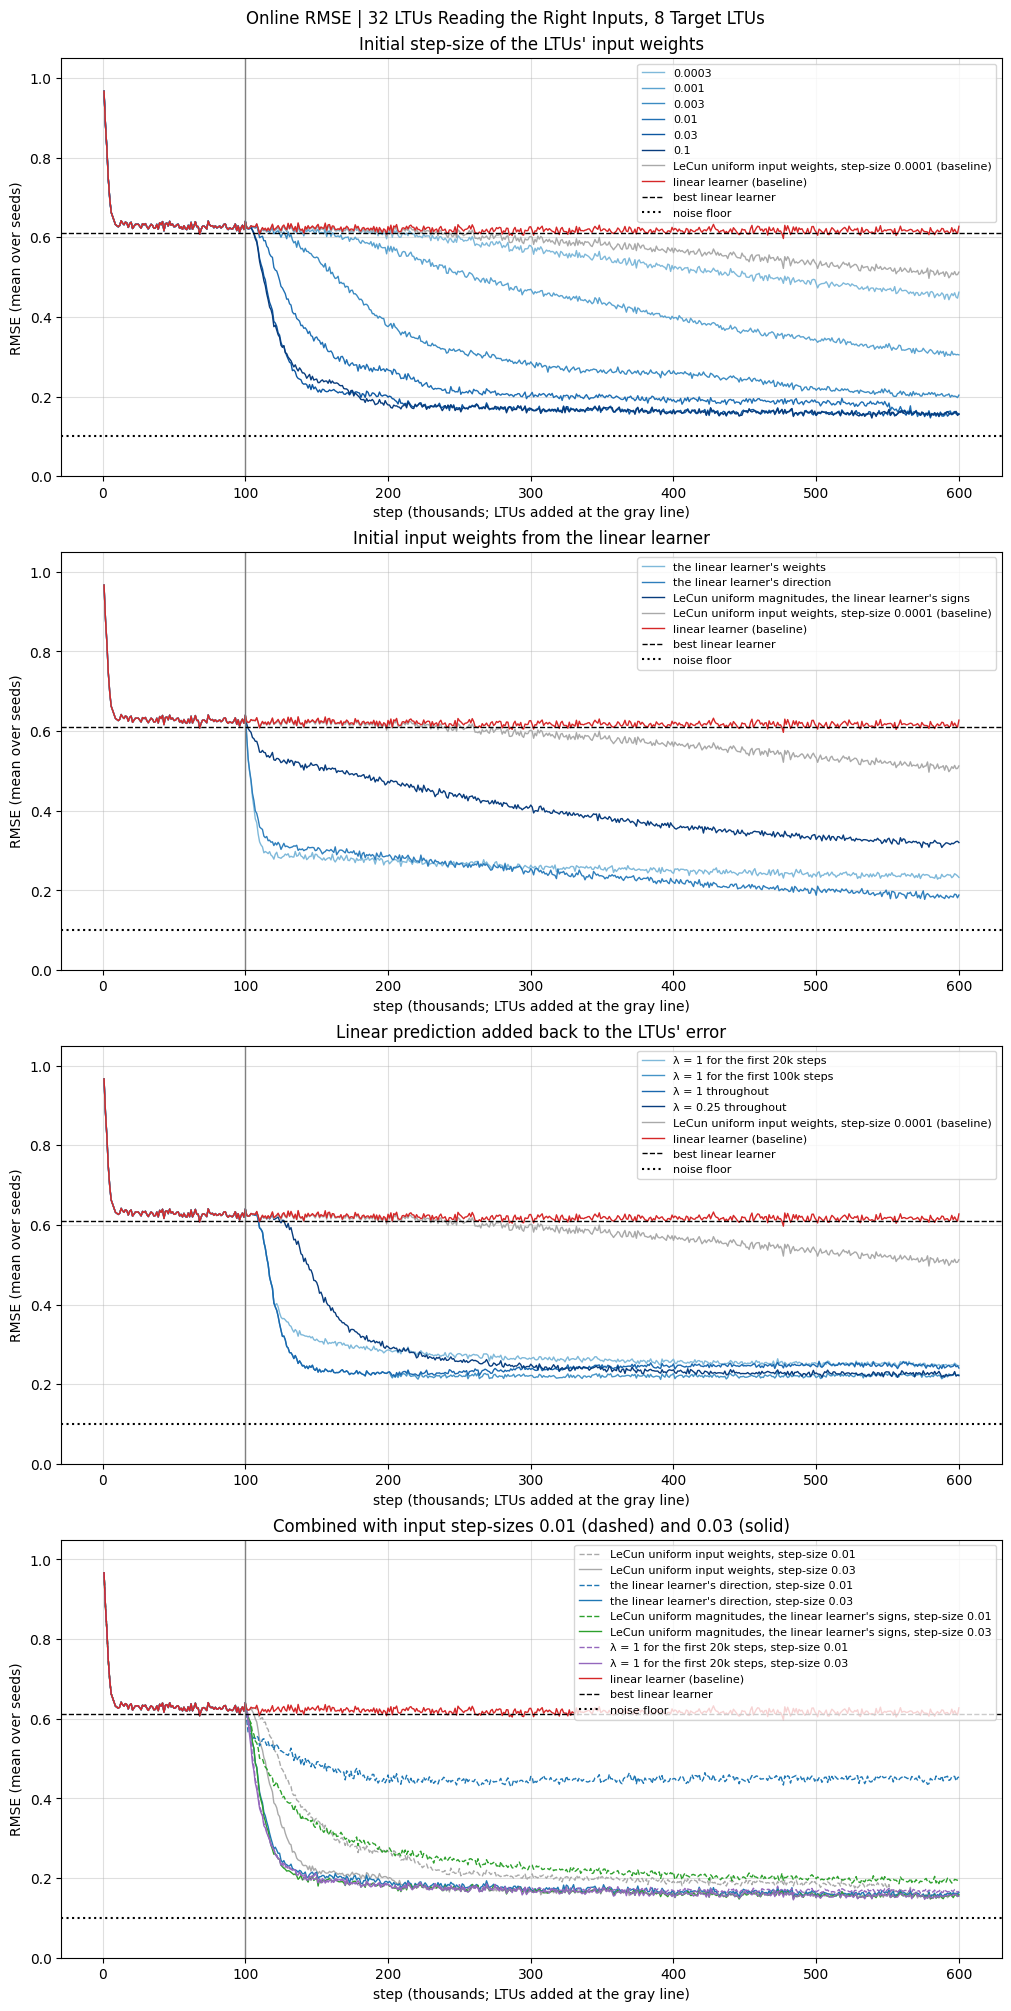

In [6]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
curve = lambda ax, rmse, **style: ax.plot(STEPS / 1000, rmse.mean(0), lw=1, **style)

fig, axes = plt.subplots(len(IDEAS) + 1, 1, figsize=(10, 5 * (len(IDEAS) + 1)), layout='constrained')
for ax, (title, variants) in zip(axes, IDEAS.items()):
    for (label, variant), color in zip(variants.items(), plt.cm.Blues(np.linspace(0.45, 0.95, len(variants)))):
        curve(ax, rmse[variant], color=color, label=label)
    curve(ax, rmse[BASELINE], color='darkgray', label=f'LeCun uniform input weights, step-size {INIT_STEP_SIZE:g} (baseline)')
    ax.set_title(title)
ax = axes[-1]
for (label, pair), color in zip(COMBINED.items(), ['darkgray', 'tab:blue', 'tab:green', 'tab:purple']):
    for variant, ls in zip(pair, ['--', '-']):
        curve(ax, rmse[variant], color=color, ls=ls, label=f'{label}, step-size {variant.input_step:g}')
ax.set_title(f'Combined with input step-sizes {COMBINED_STEPS[0]:g} (dashed) and {COMBINED_STEPS[1]:g} (solid)')
for ax in axes:
    curve(ax, linear, color='tab:red', label='linear learner (baseline)')
    ax.axvline(LINEAR_STEPS / 1000, color='gray', lw=1)
    ax.axhline(LINEAR_RMSE, color='black', ls='--', lw=1, label='best linear learner')
    ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
    ax.set(xlabel='step (thousands; LTUs added at the gray line)', ylabel='RMSE (mean over seeds)', ylim=(0, 1.05))
    ax.grid(alpha=0.4)
    ax.legend(fontsize=8)
fig.suptitle(f'Online RMSE | {N_LTUS} LTUs Reading the Right Inputs, {N_TARGETS} Target LTUs')
plt.show()

## Results

5 seeds per configuration; times are medians over seeds, counted from when the LTUs are added; final performance is
the RMSE over the last 10% of steps. The notebook takes about 2 minutes.

- **The input weights' initial step-size matters most.** Raising it from $10^{-4}$ to $3 \times 10^{-2}$ takes the LTUs
  from never reaching RMSE 0.3 in 500k steps (final 0.51) to reaching 0.3 in 30k steps and 0.2 in 46k, ending at 0.16.
  $10^{-1}$ gives the same as $3 \times 10^{-2}$.
- **At the baseline step-size, starting from the linear learner or adding its prediction back gets the LTUs going much
  sooner, but they then stall.** The linear learner's weights reach 0.3 in 13k steps, its direction in 21k, and
  $\lambda = 1$ for the first 100k steps in 29k, but they end at 0.24, 0.19 and 0.22; its signs alone are slow (0.32).
- **With step-size $3 \times 10^{-2}$, they reach 0.3 in 17k to 18k steps and 0.2 in 35k to 43k**, a little sooner than
  the step-size alone, and all end at 0.155 to 0.16. At $10^{-2}$, though, the linear learner's direction fails (0.45).
  Checked separately: at $10^{-2}$ the LTUs' input weight norm shrinks from 1 to about 0.4, which leaves their sigmoid
  derivative nearly flat, and the noise turns them away from their target LTU (|cos| 0.95); at $3 \times 10^{-2}$ the
  noise grows the norm instead, to about 5, and the direction locks in (|cos| 1.0).
- No method gets below about 0.15, against the noise floor of 0.1.